In [ ]:
import numpy as np

def calculate_conflicts(board):
    """Calculates the number of conflicts (attacking pairs) on the board."""
    n = len(board)
    conflicts = 0
    for i in range(n):
        for j in range(i + 1, n):
            # Row conflict
            if board[i] == board[j]:
                conflicts += 1
            # Diagonal conflict
            elif abs(board[i] - board[j]) == abs(i - j):
                conflicts += 1
    return conflicts

def get_neighbor(board):
    """Generates a neighbor by moving one random queen to a different row."""
    neighbor = list(board)
    col = np.random.randint(0, len(board))
    current_row = board[col]

    # Pick a different row
    available_rows = [r for r in range(len(board)) if r != current_row]
    new_row = np.random.choice(available_rows)

    neighbor[col] = new_row
    return neighbor

def simulated_annealing_8_queens(initial_temp=10.0, cooling_rate=0.99, max_iterations=5000):
    # Initialize board: 1D array where index is column, value is row
    current_board = list(range(8)) # starting with [0, 1, 2, 3, 4, 5, 6, 7] as in example
    np.random.shuffle(current_board)

    current_cost = calculate_conflicts(current_board)
    temp = initial_temp

    best_board = list(current_board)
    best_cost = current_cost

    print(f"Initial board: {current_board}, conflicts: {current_cost}\n")

    for i in range(max_iterations):
        if current_cost == 0:
            print(f"Solution found at iteration {i}!")
            break

        # Generate neighbor
        neighbor = get_neighbor(current_board)
        neighbor_cost = calculate_conflicts(neighbor)

        # Cost difference
        delta_E = neighbor_cost - current_cost

        # Acceptance criteria
        if delta_E < 0:
            # Better state
            current_board = neighbor
            current_cost = neighbor_cost
        else:
            # Worse state: accept probabilistically
            acceptance_probability = np.exp(-delta_E / temp) if temp > 0 else 0
            if np.random.rand() < acceptance_probability:
                current_board = neighbor
                current_cost = neighbor_cost

        # Keep track of absolute best
        if current_cost < best_cost:
            best_board = list(current_board)
            best_cost = current_cost

        # Cool down
        temp *= cooling_rate

    return best_board, best_cost

# Run the Simulated Annealing solver for 8-Queens
np.random.seed(42)
best_solution, final_cost = simulated_annealing_8_queens(initial_temp=10.0, cooling_rate=0.99, max_iterations=10000)

print(f"\nFinal Board Configuration: {best_solution}")
print(f"Remaining Conflicts: {final_cost}")

Initial board: [1, 5, 0, 7, 2, 4, 3, 6], conflicts: 5

Solution found at iteration 1027!

Final Board Configuration: [np.int64(1), np.int64(6), np.int64(4), np.int64(7), np.int64(0), np.int64(3), np.int64(5), np.int64(2)]
Remaining Conflicts: 0


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128081 (\N{CROWN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


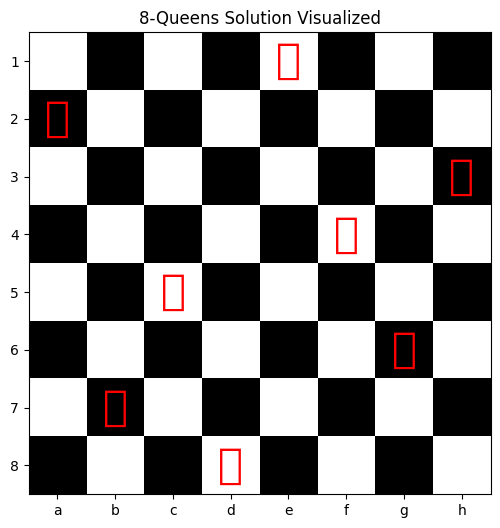

In [ ]:
def plot_board(board):
    """Helper function to visualize the chessboard."""
    n = len(board)
    grid = np.zeros((n, n))
    # Create chessboard pattern
    grid[1::2, ::2] = 0.5
    grid[::2, 1::2] = 0.5

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(grid, cmap='binary', origin='upper')

    # Draw Queens
    for col, row in enumerate(board):
        ax.text(col, row, '👑', fontsize=30, ha='center', va='center', color='red')

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels([chr(97 + i) for i in range(n)]) # a-h labels
    ax.set_yticklabels(range(1, n + 1))
    plt.title("8-Queens Solution Visualized")
    plt.show()

plot_board(best_solution)